# COMP3602 — Week 3 Lab: Data Presentation with Matplotlib
### Scenario
The Student Affairs Office collected a synthetic survey from **120 students**. Your task is to answer practical questions by choosing and creating an appropriate visualization.

### Important rule
The question will **not tell you which chart to use**. Decide from:
- the type of data,
- what the question is asking,
- and the Week 3 concepts.

You will use all graphical methods studied in Week 3: **simple bar chart, multiple bar chart, stacked bar chart, pie chart, histogram, frequency polygon, less-than ogive, and more-than ogive**.

You will also construct a grouped frequency distribution for `Quiz_Score`.

#### Instructions 
1. When saving the file, replace "StudentID" with your own Student ID and keep the rest of the file name unchanged.
2. DO NOT create or add any additional cells. Write your code only in the provided spaces.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('student_campus_data.csv')
print(df.shape)

(120, 9)


## Task 1 — How are quiz scores distributed?
The course coordinator wants to know **where quiz scores are concentrated and how the scores are distributed**.

Choose the most appropriate Week 3 visualization and create it. Use **6 bins**. Add a title and axis labels.

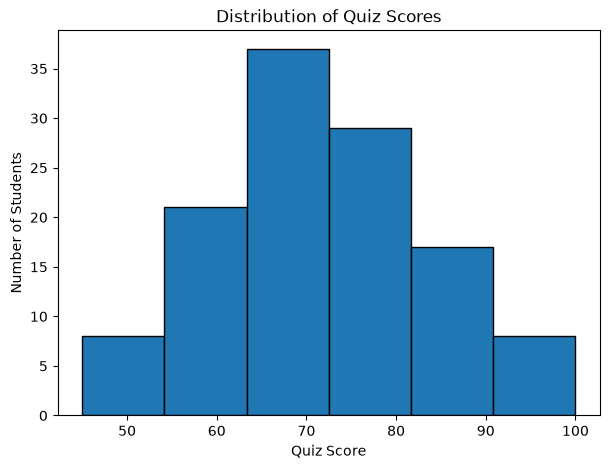

In [2]:
# Quiz_Score is numerical (continuous) -> HISTOGRAM shows where scores are concentrated
plt.figure(figsize=(7, 5))
plt.hist(df['Quiz_Score'], bins=6, edgecolor='black')
plt.title('Distribution of Quiz Scores')
plt.xlabel('Quiz Score')
plt.ylabel('Number of Students')
plt.show()

## Task 2 — Does learning-mode preference differ by gender?
Compare the numbers of **Female and Male students** choosing each `Learning_Mode`.

Create the most appropriate visualization for comparing the two groups side-by-side.

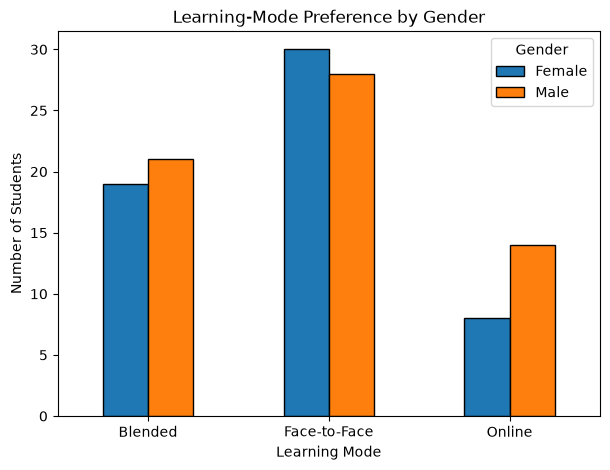

In [3]:
# Two categorical variables (Gender x Learning_Mode), compare groups side by side -> MULTIPLE (grouped) BAR CHART
ct = pd.crosstab(df['Learning_Mode'], df['Gender'])
ct.plot(kind='bar', figsize=(7, 5), edgecolor='black')
plt.title('Learning-Mode Preference by Gender')
plt.xlabel('Learning Mode')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.show()

## Task 3 — How is campus transportation divided?
Student Affairs wants to communicate the **percentage share** of students using each `Transport_Mode`.

Create the most appropriate visualization. Display the percentage on each part.

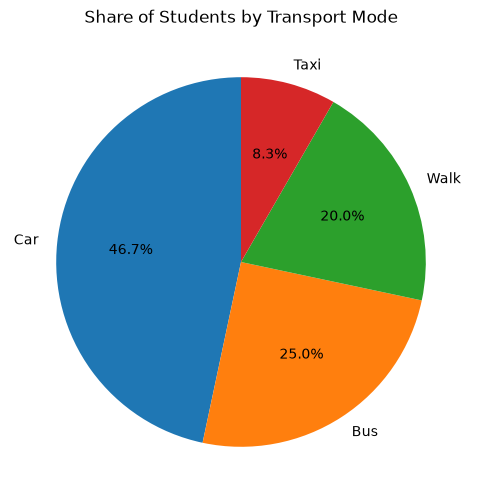

In [4]:
# Percentage share of parts of a whole (categorical) -> PIE CHART
transport = df['Transport_Mode'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(transport.values, labels=transport.index, autopct='%1.1f%%', startangle=90)
plt.title('Share of Students by Transport Mode')
plt.show()

## Task 4 — Build a grouped frequency distribution for Quiz Score
Before drawing cumulative-frequency graphs, construct a grouped frequency distribution.

Use these fixed class boundaries:

`40, 50, 60, 70, 80, 90, 100`

Calculate:
1. frequency,
2. lower boundaries,
3. upper boundaries,
4. class midpoints,
5. less-than cumulative frequency,
6. more-than cumulative frequency.

Display the completed table.

In [5]:
# Grouped frequency distribution of Quiz_Score
boundaries = [40, 50, 60, 70, 80, 90, 100]
# np.histogram: classes are [lower, upper) except the last, which also includes 100
freq, _ = np.histogram(df['Quiz_Score'], bins=boundaries)

freq_table = pd.DataFrame({
    'Class': [f'{boundaries[i]}-{boundaries[i+1]}' for i in range(6)],
    'Frequency': freq,
    'Lower Boundary': boundaries[:-1],
    'Upper Boundary': boundaries[1:],
})
freq_table['Midpoint'] = (freq_table['Lower Boundary'] + freq_table['Upper Boundary']) / 2
freq_table['Less-than CF'] = freq_table['Frequency'].cumsum()
freq_table['More-than CF'] = freq_table['Frequency'][::-1].cumsum()[::-1]
print('Total frequency:', freq_table['Frequency'].sum(), 'of', len(df))
freq_table

Total frequency: 120 of 120


,Class,Frequency,Lower Boundary,Upper Boundary,Midpoint,Less-than CF,More-than CF
0,40-50,4,40,50,45.0,4,120
1,50-60,13,50,60,55.0,17,116
2,60-70,31,60,70,65.0,48,103
3,70-80,36,70,80,75.0,84,72
4,80-90,27,80,90,85.0,111,36
5,90-100,9,90,100,95.0,120,9


## Task 5 — How many students scored below different thresholds?
Using the frequency distribution from Task 4, create a graph that shows **how the number of students accumulates as the score threshold increases**.

Use the appropriate class boundaries on the x-axis.

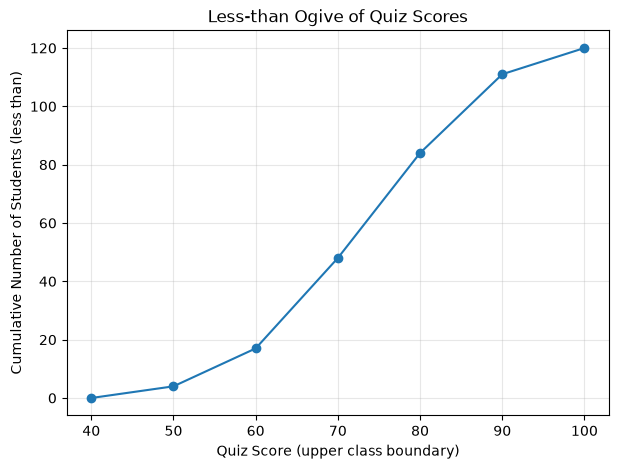

In [6]:
# Number of students BELOW a threshold -> LESS-THAN OGIVE (upper boundaries vs less-than cumulative frequency)
x = [40] + list(freq_table['Upper Boundary'])
y = [0] + list(freq_table['Less-than CF'])
plt.figure(figsize=(7, 5))
plt.plot(x, y, marker='o')
plt.title('Less-than Ogive of Quiz Scores')
plt.xlabel('Quiz Score (upper class boundary)')
plt.ylabel('Cumulative Number of Students (less than)')
plt.xticks(boundaries)
plt.grid(True, alpha=0.3)
plt.show()

## Task 6 — Which learning activity is most popular?
The instructor wants to compare the number of students preferring each `Preferred_Activity`.

Create the most appropriate visualization and identify the most popular activity.

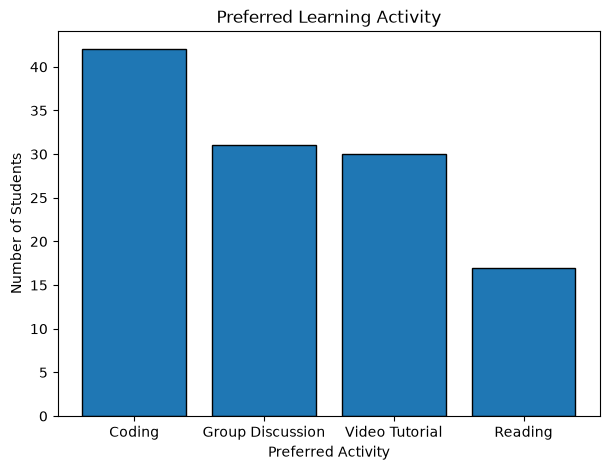

Most popular activity: Coding ( 42 students )


In [7]:
# Compare counts of categories -> SIMPLE BAR CHART
activity = df['Preferred_Activity'].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(activity.index, activity.values, edgecolor='black')
plt.title('Preferred Learning Activity')
plt.xlabel('Preferred Activity')
plt.ylabel('Number of Students')
plt.show()
print('Most popular activity:', activity.idxmax(), '(', activity.max(), 'students )')

## Task 7 — Compare two quiz-score distributions
Compare the **shape of the quiz-score distributions** for `Year 1` and `Year 4` students on the same graph.

Use the same class boundaries from Task 4. The graph should use **class marks** and **frequencies**.

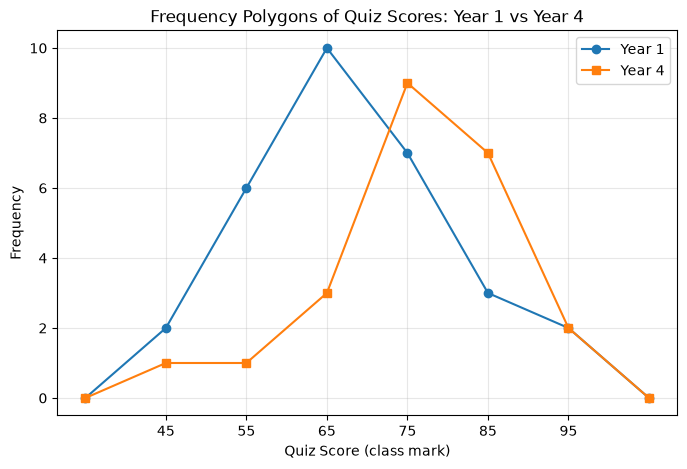

In [8]:
# Compare the SHAPE of two distributions on the same graph -> FREQUENCY POLYGONS (midpoints vs frequency)
f1, _ = np.histogram(df.loc[df['Year_Level'] == 'Year 1', 'Quiz_Score'], bins=boundaries)
f4, _ = np.histogram(df.loc[df['Year_Level'] == 'Year 4', 'Quiz_Score'], bins=boundaries)
mids = list(freq_table['Midpoint'])
# add empty classes at both ends so each polygon closes on the x-axis
mids_closed = [35] + mids + [105]
plt.figure(figsize=(8, 5))
plt.plot(mids_closed, [0] + list(f1) + [0], marker='o', label='Year 1')
plt.plot(mids_closed, [0] + list(f4) + [0], marker='s', label='Year 4')
plt.title('Frequency Polygons of Quiz Scores: Year 1 vs Year 4')
plt.xlabel('Quiz Score (class mark)')
plt.ylabel('Frequency')
plt.xticks(mids)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Task 8 — What is the year-level composition of each faculty?
For each `Faculty`, Student Affairs wants to see:
- the **total number of surveyed students**, and
- how that total is **composed of Year 1, Year 2, Year 3, and Year 4 students**.

Create the most appropriate visualization.

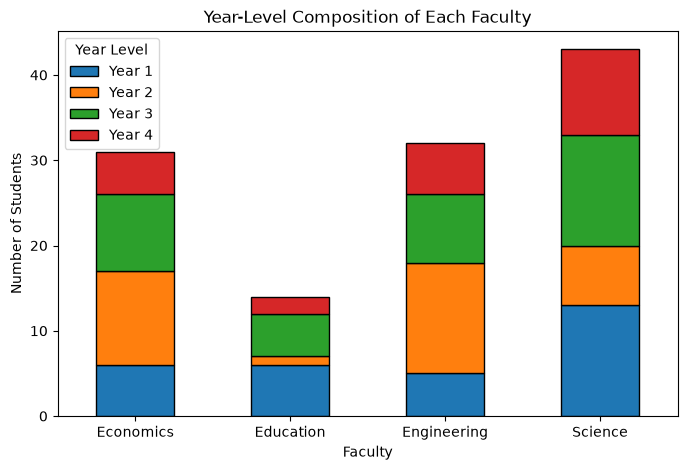

In [9]:
# Total per faculty AND its composition by year -> STACKED BAR CHART
comp = pd.crosstab(df['Faculty'], df['Year_Level'])
comp.plot(kind='bar', stacked=True, figsize=(8, 5), edgecolor='black')
plt.title('Year-Level Composition of Each Faculty')
plt.xlabel('Faculty')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)
plt.legend(title='Year Level')
plt.show()

## Task 9 — How many students scored at or above different thresholds?
The coordinator now wants the opposite cumulative view: **how many observations remain at or above each increasing score threshold?**

Use the frequency distribution from Task 4 and create the appropriate graph.

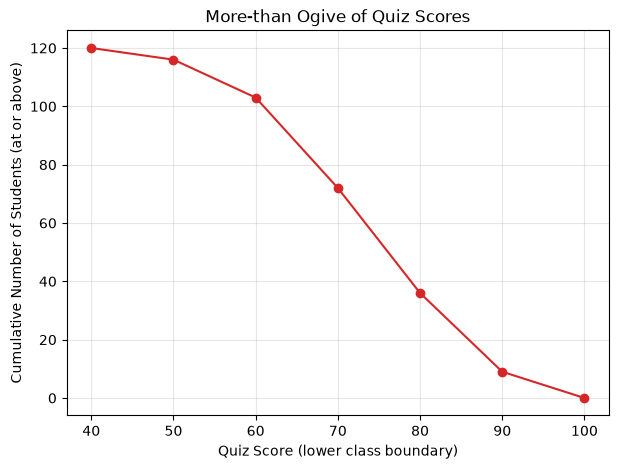

In [10]:
# Number of students AT OR ABOVE a threshold -> MORE-THAN OGIVE (lower boundaries vs more-than cumulative frequency)
x = list(freq_table['Lower Boundary']) + [100]
y = list(freq_table['More-than CF']) + [0]
plt.figure(figsize=(7, 5))
plt.plot(x, y, marker='o', color='tab:red')
plt.title('More-than Ogive of Quiz Scores')
plt.xlabel('Quiz Score (lower class boundary)')
plt.ylabel('Cumulative Number of Students (at or above)')
plt.xticks(boundaries)
plt.grid(True, alpha=0.3)
plt.show()

## Task 10 — Final Visualization Decision
The university wants to know **which faculty has the largest number of surveyed students**.

Choose and create the best visualization. Then write **one sentence** interpreting the result.

> Do not choose a graph simply because it has not been used recently. Base your choice on the question.


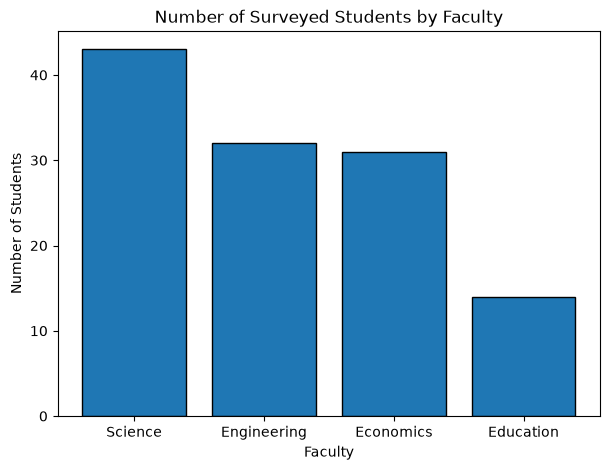

Interpretation: Science has the largest number of surveyed students (43 out of 120).


In [11]:
# Compare totals of categories -> SIMPLE BAR CHART
faculty = df['Faculty'].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(faculty.index, faculty.values, edgecolor='black')
plt.title('Number of Surveyed Students by Faculty')
plt.xlabel('Faculty')
plt.ylabel('Number of Students')
plt.show()
print(f'Interpretation: {faculty.idxmax()} has the largest number of surveyed students ({faculty.max()} out of {len(df)}).')

## Lab Reflection
For each visualization used today, be able to explain **why it was appropriate for the question**.

The central idea of Week 3 is:

**Question → Data Type → Appropriate Presentation → Interpretation**
